## Author: Gabriel Vance
## Class: DSC540 - Data Preparation
## Professor: Catherine Williams
## Date: June 27, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 3/4 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Packages/Data Formats/Data Structures/Data Sources

##  Activity 3.01, page 155

### 1. Load the necessary libraries.


In [3]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import pandas as pd

### 2. Read in the Boston Housing dataset (given as a csv file) from the local directory.


In [4]:
boston_df = pd.read_csv('Boston_housing.csv')
boston_df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


### 3. Check the first 10 records. Find the total number of records.



In [5]:
# Display the first 10 records
boston_df.head(10)

# Find the total number of records
total_records = len(boston_df)
print(f"Total number of records: {total_records}")

Total number of records: 506


### 4. Create a smaller DataFrame with columns that do not include CHAS, NOX, B, and LSTART.



In [6]:
# Create a smaller DataFrame excluding 'CHAS', 'NOX', 'B', and 'LSTAT'
refined_df = boston_df.drop(columns=['CHAS', 'NOX', 'B', 'LSTAT'])
# Chas: Charlse River Dummy variable
# Nox: Nitric Oxide concentration
# B: Proportion of the population that is African American
# LSTAT: Percentage of lower-income population
refined_df.head()

,CRIM,ZN,INDUS,RM,AGE,DIS,RAD,TAX,PTRATIO,PRICE
0,0.00632,18.0,2.31,6.575,65.2,4.0900,1,296,15.3,24.0
1,0.02731,0.0,7.07,6.421,78.9,4.9671,2,242,17.8,21.6
2,0.02729,0.0,7.07,7.185,61.1,4.9671,2,242,17.8,34.7
3,0.03237,0.0,2.18,6.998,45.8,6.0622,3,222,18.7,33.4
4,0.06905,0.0,2.18,7.147,54.2,6.0622,3,222,18.7,36.2


### 5. Check the last seven records of the new DataFrame you just created.

In [7]:
# Use tail() for the last seven records
refined_df.tail(7)

,CRIM,ZN,INDUS,RM,AGE,DIS,RAD,TAX,PTRATIO,PRICE
499,0.17783,0.0,9.69,5.569,73.5,2.3999,6,391,19.2,17.5
500,0.22438,0.0,9.69,6.027,79.7,2.4982,6,391,19.2,16.8
501,0.06263,0.0,11.93,6.593,69.1,2.4786,1,273,21.0,22.4
502,0.04527,0.0,11.93,6.120,76.7,2.2875,1,273,21.0,20.6
503,0.06076,0.0,11.93,6.976,91.0,2.1675,1,273,21.0,23.9
504,0.10959,0.0,11.93,6.794,89.3,2.3889,1,273,21.0,22.0
505,0.04741,0.0,11.93,6.030,80.8,2.5050,1,273,21.0,11.9


### 6. Plot the histograms of all the variables (columns) in the new DataFrame.

array([[<Axes: title={'center': 'CRIM'}>, <Axes: title={'center': 'ZN'}>,
        <Axes: title={'center': 'INDUS'}>],
       [<Axes: title={'center': 'RM'}>, <Axes: title={'center': 'AGE'}>,
        <Axes: title={'center': 'DIS'}>],
       [<Axes: title={'center': 'RAD'}>, <Axes: title={'center': 'TAX'}>,
        <Axes: title={'center': 'PTRATIO'}>],
       [<Axes: title={'center': 'PRICE'}>, <Axes: >, <Axes: >]],
      dtype=object)

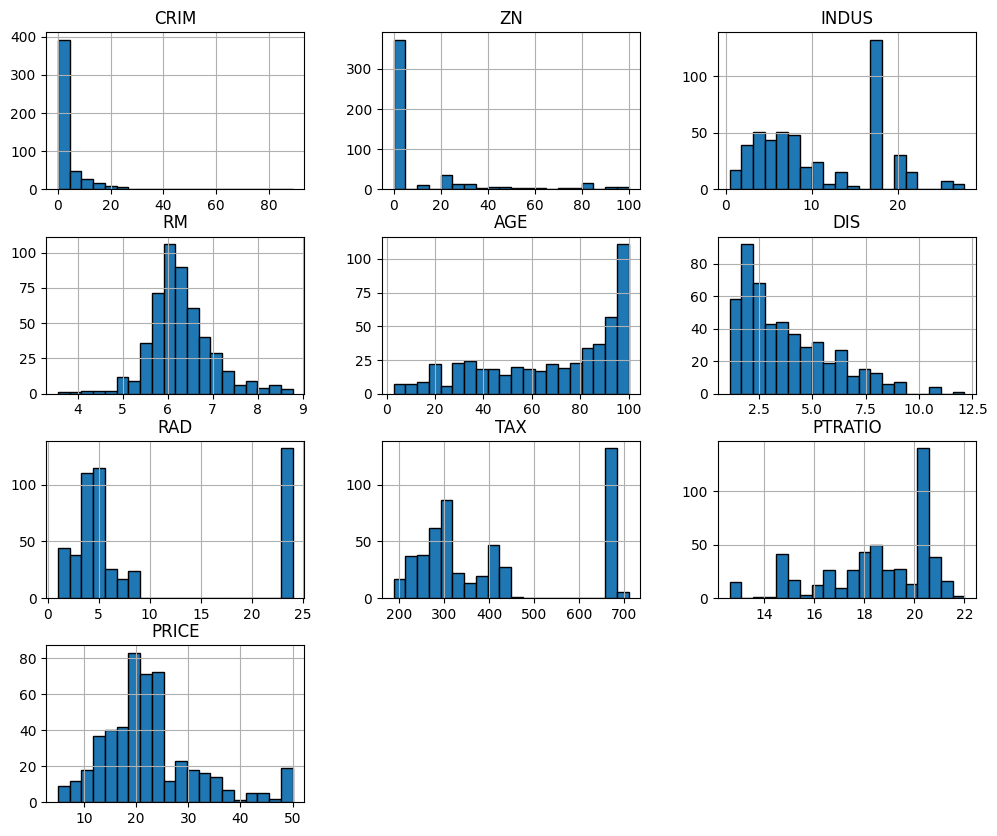

In [8]:
# Plot histograms for all columns in refined_df
refined_df.hist(figsize=(12, 10), bins=20, edgecolor='black')

### 7. Plot them all at once using a for loop. Try to add a unique title to the plot.

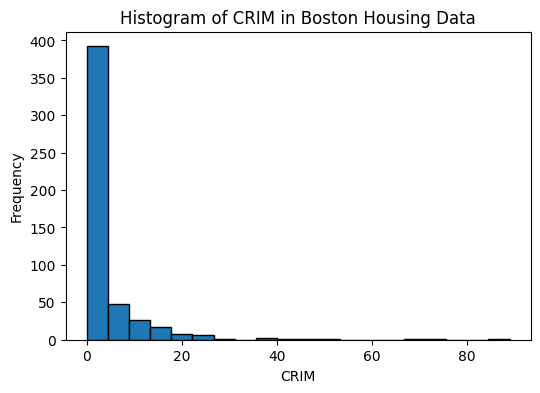

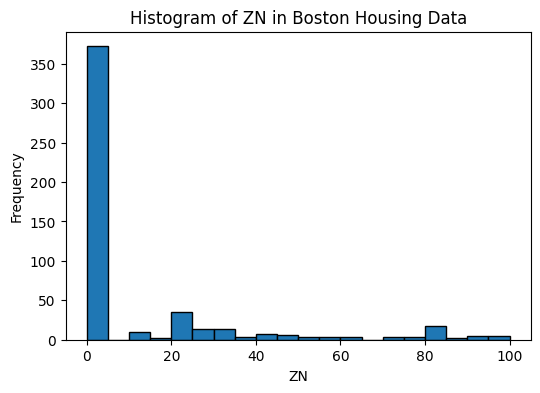

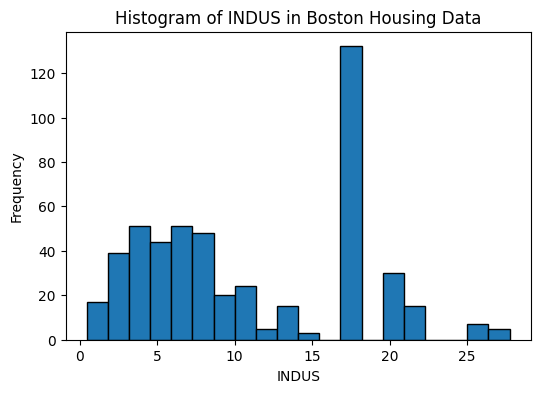

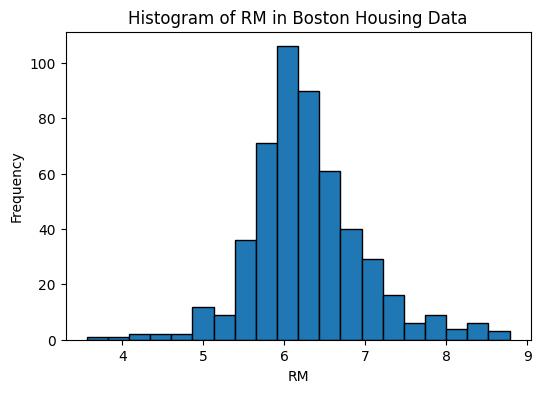

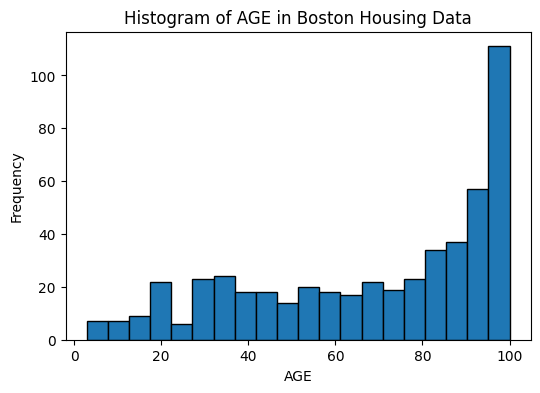

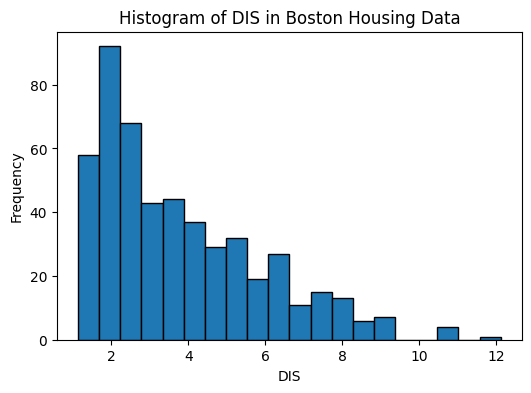

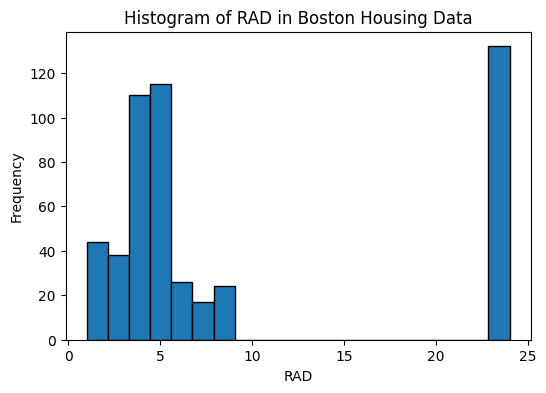

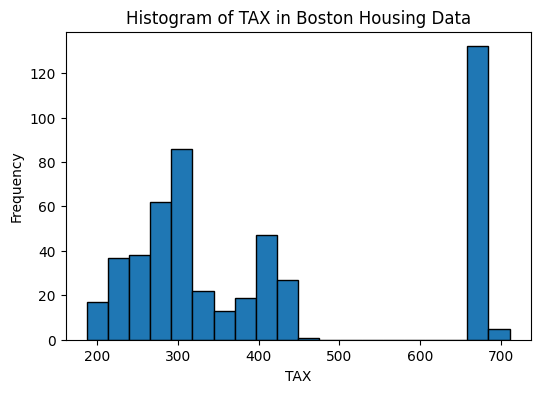

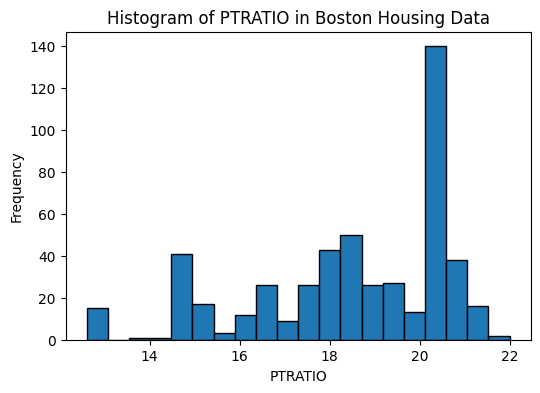

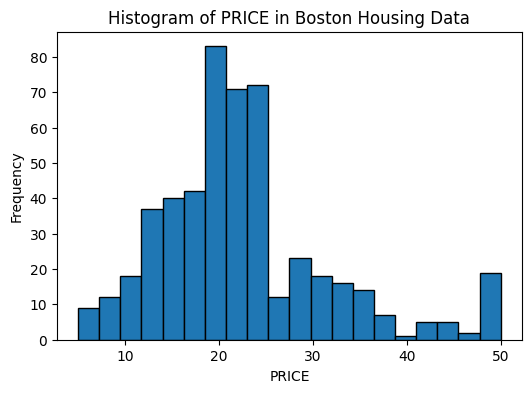

In [9]:

# Plot each column in refined_df with a unique title
for col in refined_df.columns:
    plt.figure(figsize=(6, 4))
    plt.hist(refined_df[col], bins=20, edgecolor='black')
    plt.title(f'Histogram of {col} in Boston Housing Data')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

### 8. Create a scatter plot of crime rate versus price.

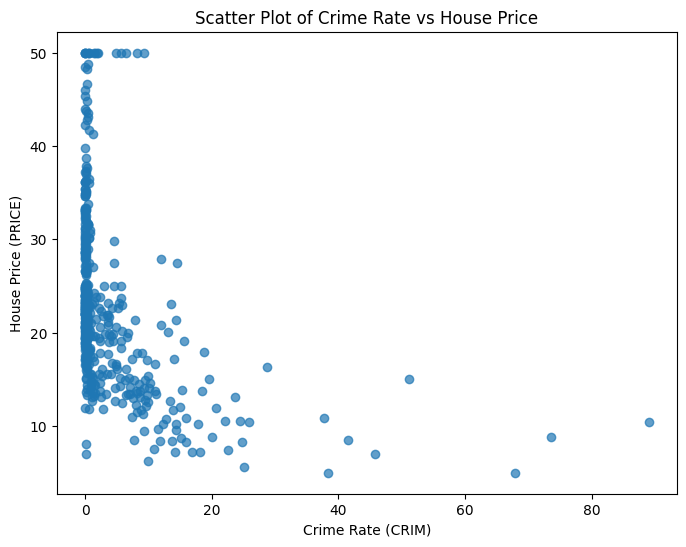

In [10]:
# Scatter plot of crime rate (CRIM) vs price (PRICE)
plt.figure(figsize=(8, 6))
plt.scatter(boston_df['CRIM'], boston_df['PRICE'], alpha=0.7)
plt.xlabel('Crime Rate (CRIM)')
plt.ylabel('House Price (PRICE)')
plt.title('Scatter Plot of Crime Rate vs House Price')
plt.show()

### 9. Plot log10(crime) versus price.

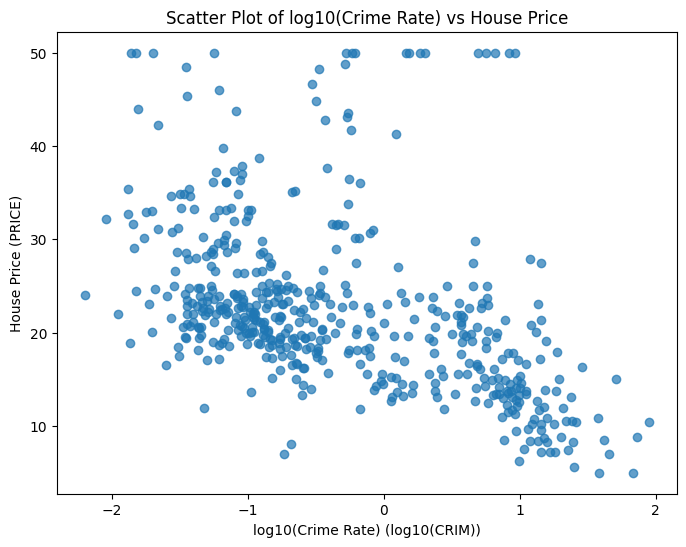

In [11]:
import numpy as np

plt.figure(figsize=(8, 6))
plt.scatter(np.log10(boston_df['CRIM']), boston_df['PRICE'], alpha=0.7)
plt.xlabel('log10(Crime Rate) (log10(CRIM))')
plt.ylabel('House Price (PRICE)')
plt.title('Scatter Plot of log10(Crime Rate) vs House Price')
plt.show()

### 10. Calculate some useful statistics, such as mean rooms per dwelling, median age, mean distances to five Boston employment centers, and the percentage of houses with a low price (< $20,000).

In [12]:
# Mean rooms per dwelling
mean_rooms = boston_df['RM'].mean()

# Median age
median_age = boston_df['AGE'].median()

# Mean distance to five Boston employment centers
mean_distance = boston_df['DIS'].mean()

# Percentage of houses with a low price (< $20,000)
low_price_percentage = (boston_df['PRICE'] < 20).mean() * 100

print(f"Mean rooms per dwelling: {mean_rooms:.2f}")
print(f"Median age: {median_age:.2f}")
print(f"Mean distance to employment centers: {mean_distance:.2f}")
print(f"Percentage of houses with price < $20,000: {low_price_percentage:.2f}%")

Mean rooms per dwelling: 6.28
Median age: 77.50
Mean distance to employment centers: 3.80
Percentage of houses with price < $20,000: 41.50%


## Activity 4.01: Working with the Adult Income Dataset (UCI)

### 1. Read the adult income dataset from the following URL: https://packt.live/2N9lRUU.

In [13]:
adult_income_df = pd.read_csv('adult_income_data.csv')
adult_income_df.head()

,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,Male,2174,0,40,United-States,<=50K
0,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,Male,0,0,13,United-States,<=50K
1,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,Male,0,0,40,United-States,<=50K
2,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Male,0,0,40,United-States,<=50K
3,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Female,0,0,40,Cuba,<=50K
4,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,Female,0,0,40,United-States,<=50K


### 2. Create a script that will read a text file line by line.

In [14]:
def read_file_line_by_line(file_path):
    with open(file_path, 'r') as file:
        for line in file:
            print(line.rstrip())

### 3. Add a name of Income for the response variable to the dataset.

In [15]:
# Rename the response variable column to 'Income'
adult_income_df = adult_income_df.rename(columns={adult_income_df.columns[-1]: 'Income'})
adult_income_df.head()

,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,Male,2174,0,40,United-States,Income
0,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,Male,0,0,13,United-States,<=50K
1,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,Male,0,0,40,United-States,<=50K
2,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Male,0,0,40,United-States,<=50K
3,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Female,0,0,40,Cuba,<=50K
4,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,Female,0,0,40,United-States,<=50K


### 4. Find the missing values.

In [16]:
# Find missing values in the adult_income_df DataFrame
missing_values = adult_income_df.isnull().sum()
print("Missing values per column:")
print(missing_values)

Missing values per column:
39                0
 State-gov        0
77516             0
 Bachelors        0
13                0
 Never-married    0
 Adm-clerical     0
 Not-in-family    0
 Male             0
2174              0
0                 0
40                0
 United-States    0
Income            0
dtype: int64


### 5. Create a DataFrame with only age, education, and occupation by using subsetting.

In [17]:
# Subset the DataFrame to include only age, education, and occupation columns
age_education_occupation_df = adult_income_df.iloc[:, [0, 3, 6]]
age_education_occupation_df.head()

,39,Bachelors,Adm-clerical
0,50,Bachelors,Exec-managerial
1,38,HS-grad,Handlers-cleaners
2,53,11th,Handlers-cleaners
3,28,Bachelors,Prof-specialty
4,37,Masters,Exec-managerial


### 6. Plot a histogram of age with a bin size of 20

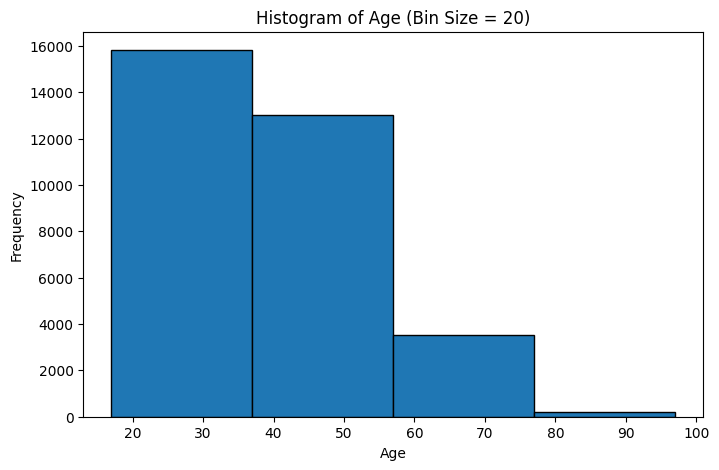

In [18]:
# Plot a histogram of age with a bin size of 20
plt.figure(figsize=(8, 5))
plt.hist(adult_income_df.iloc[:, 0], bins=range(int(adult_income_df.iloc[:, 0].min()), int(adult_income_df.iloc[:, 0].max()) + 20, 20), edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Histogram of Age (Bin Size = 20)')
plt.show()

### 7. Create a function to strip the whitespace characters.

In [19]:
# Function to strip whitespace characters from a string
def strip_whitespace(x):
    if isinstance(x, str):
        return x.strip()
    return x

### 8. Use the apply method to apply this function to all the columns with string values, create a new column, copy the values from this new column to the old column, and drop the new column.

In [20]:
# Apply strip_whitespace to all string columns, create a temp column, copy back, then drop temp
for col in adult_income_df.columns:
    if adult_income_df[col].dtype == 'object':
        temp_col = col + '_stripped'
        adult_income_df[temp_col] = adult_income_df[col].apply(strip_whitespace)
        adult_income_df[col] = adult_income_df[temp_col]
        adult_income_df = adult_income_df.drop(columns=[temp_col])

### 9. Find the number of people who are aged between 30 and 50.

In [21]:
# Find the number of people aged between 30 and 50 (inclusive)
age_col = adult_income_df.columns[0]  # The first column is age
num_people_30_50 = adult_income_df[(adult_income_df[age_col] >= 30) & (adult_income_df[age_col] <= 50)].shape[0]
print(f"Number of people aged between 30 and 50: {num_people_30_50}")

Number of people aged between 30 and 50: 16389


### 10. Group the records based on age and education to find how the mean age is distributed.

In [22]:
# Group by age and education, then calculate the mean age for each education group
age_col = adult_income_df.columns[0]        # Age column
education_col = adult_income_df.columns[3]  # Education column

mean_age_by_education = adult_income_df.groupby(education_col)[age_col].mean().sort_values()
print("Mean age by education level:")
print(mean_age_by_education)

Mean age by education level:
 Bachelors
12th            32.000000
11th            32.355745
Some-college    35.756275
Assoc-acdm      37.381443
10th            37.429796
Assoc-voc       38.553546
Bachelors       38.904931
HS-grad         38.974479
9th             41.060311
Preschool       42.764706
5th-6th         42.885886
Masters         44.049913
Prof-school     44.746528
1st-4th         46.142857
Doctorate       47.702179
7th-8th         48.445820
Name: 39, dtype: float64


### 11. Group by occupation and show the summary statistics of age. Find which profession has the oldest workers on average and which profession has its largest share of the workforce above the 75th percentile.

In [23]:
# Group by occupation and show summary statistics of age
occupation_col = adult_income_df.columns[6]  # Occupation column
age_col = adult_income_df.columns[0]         # Age column

# Summary statistics of age by occupation
age_stats_by_occupation = adult_income_df.groupby(occupation_col)[age_col].describe()
print("Summary statistics of age by occupation:")
print(age_stats_by_occupation)

# Find the profession with the oldest workers on average
mean_ages = adult_income_df.groupby(occupation_col)[age_col].mean()
oldest_profession = mean_ages.idxmax()
print(f"\nProfession with the oldest workers on average: {oldest_profession} ({mean_ages.max():.2f} years)")

# Find the 75th percentile of age for the whole dataset
age_75th = adult_income_df[age_col].quantile(0.75)

# Calculate the share of workforce above the 75th percentile for each occupation
share_above_75th = adult_income_df.groupby(occupation_col).apply(
    lambda x: (x[age_col] > age_75th).mean()
)

largest_share_profession = share_above_75th.idxmax()
print(f"Profession with the largest share of workforce above the 75th percentile: {largest_share_profession} ({share_above_75th.max()*100:.2f}%)")

Summary statistics of age by occupation:
                    count       mean        std   min   25%   50%   75%   max
 Adm-clerical                                                                
?                  1843.0  40.882800  20.336350  17.0  21.0  35.0  61.0  90.0
Adm-clerical       3769.0  36.963916  13.364730  17.0  26.0  35.0  46.0  90.0
Armed-Forces          9.0  30.222222   8.089774  23.0  24.0  29.0  34.0  46.0
Craft-repair       4099.0  39.031471  11.606436  17.0  30.0  38.0  47.0  90.0
Exec-managerial    4066.0  42.169208  11.974548  17.0  33.0  41.0  50.0  90.0
Farming-fishing     994.0  41.211268  15.070283  17.0  29.0  39.0  52.0  90.0
Handlers-cleaners  1370.0  32.165693  12.372635  17.0  23.0  29.0  39.0  90.0
Machine-op-inspct  2002.0  37.715285  12.068266  17.0  28.0  36.0  46.0  90.0
Other-service      3295.0  34.949621  14.521508  17.0  22.0  32.0  45.0  90.0
Priv-house-serv     149.0  41.724832  18.633688  17.0  24.0  40.0  57.0  81.0
Prof-specialty     4140

C:\Users\Gabe\AppData\Local\Temp\ipykernel_31960\3355468494.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  share_above_75th = adult_income_df.groupby(occupation_col).apply(


### 12. Use subset and groupBy to find the outliers.

In [24]:
# We'll identify outliers in 'age' by occupation using the IQR method

occupation_col = adult_income_df.columns[6]  # Occupation column
age_col = adult_income_df.columns[0]         # Age column

# Calculate Q1, Q3, and IQR for age within each occupation
def find_outliers(group):
    Q1 = group[age_col].quantile(0.25)
    Q3 = group[age_col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return group[(group[age_col] < lower) | (group[age_col] > upper)]

outliers_df = adult_income_df.groupby(occupation_col, group_keys=False).apply(find_outliers)
print("Outliers in age by occupation:")
print(outliers_df[[age_col, occupation_col]])

Outliers in age by occupation:
       39      Adm-clerical
2890   90      Adm-clerical
3536   81      Adm-clerical
4833   81      Adm-clerical
5271   90      Adm-clerical
6589   77      Adm-clerical
...    ..               ...
24289  72      Tech-support
30021  70      Tech-support
15355  90  Transport-moving
26901  78  Transport-moving
28947  81  Transport-moving

[178 rows x 2 columns]


C:\Users\Gabe\AppData\Local\Temp\ipykernel_31960\785532158.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  outliers_df = adult_income_df.groupby(occupation_col, group_keys=False).apply(find_outliers)


### 13. Plot the outlier values on a bar chart.

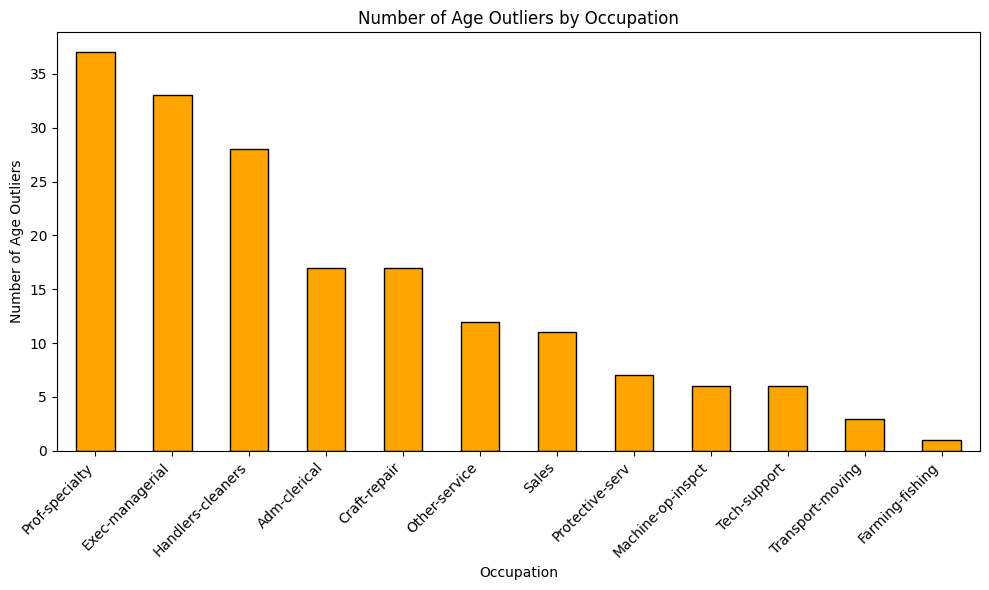

In [25]:
# Plot the number of outliers in age for each occupation as a bar chart

# Count outliers per occupation
outlier_counts = outliers_df[occupation_col].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
outlier_counts.plot(kind='bar', color='orange', edgecolor='black')
plt.xlabel('Occupation')
plt.ylabel('Number of Age Outliers')
plt.title('Number of Age Outliers by Occupation')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 14. Merge the two DataFrames using common keys to drop duplicate values.

In [27]:
# Merge refined_df and smaller_df on all columns to find duplicates and drop them
merged_df = pd.merge(refined_df, outliers_df).drop_duplicates()
print(f"Number of records after merging and dropping duplicates: {len(merged_df)}")
merged_df.head()

MergeError: No common columns to perform merge on. Merge options: left_on=None, right_on=None, left_index=False, right_index=False

## Activity 5.01: Reading Tabular Data from a Web Page and Creating DataFrames

### 1. Open the page in a separate Chrome/Firefox tab and use something like an Inspect Element tool to view the source HTML and understand its structure.

### 2. Read the page using bs4.

In [28]:
from bs4 import BeautifulSoup
import requests

url = 'https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal'
response = requests.get(url)
soup = BeautifulSoup(response.content, 'html.parser')
print(soup.prettify()[:1000])  # Print the first 1000 characters for inspection

<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 vector-feature-night-mode-enabled skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-not-available" dir="ltr" lang="en">
 <head>
  <meta charset="utf-8"/>
  <title>
   List of countries by GDP (nominal - Wikipedia
  </title>
  <script>
   (function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature

### 3. Find the table structure you will need to deal with (how many tables are there?).

In [29]:
# Find all tables in the parsed HTML soup and print the number of tables
tables = soup.find_all('table')
print(f"Number of tables found on the page: {len(tables)}")

Number of tables found on the page: 2


### 4. Find the right table using bs4.

In [30]:
# Since the page did not load the expected GDP tables (likely due to a typo or missing page),
# let's print the first few rows of each table to inspect their content.

for i, table in enumerate(tables):
    print(f"\nTable {i}:")
    print(table.prettify()[:500])  # Print the first 500 characters of each table for inspection


Table 0:
<table class="plainlinks fmbox fmbox-editnotice" id="newarticletext" role="presentation">
 <tbody>
  <tr>
   <td class="mbox-image">
    <span typeof="mw:File">
     <span>
      <img alt="" class="mw-file-element" data-file-height="48" data-file-width="48" decoding="async" height="40" src="//upload.wikimedia.org/wikipedia/commons/thumb/e/e7/Dialog-information_on.svg/40px-Dialog-information_on.svg.png" srcset="//upload.wikimedia.org/wikipedia/commons/thumb/e/e7/Dialog-information_on.svg/60px-Dia

Table 1:
<table class="plainlinks fmbox fmbox-system" id="noarticletext" role="presentation">
 <tbody>
  <tr>
   <td class="mbox-text" style="padding: 0.6em 0.9em;">
    <style data-mw-deduplicate="TemplateStyles:r1227763082">
     .mw-parser-output .no-article-text-sister-projects{border:1px solid #a2a9b1;background-color:#f8f9fa;background-color:var(--background-color-neutral-subtle,#f8f9fa);line-height:1.5em;font-size:90%;padding:0.5em}.mw-parser-output .no-article-text-sister-pro

### 5. Separate the source names and their corresponding data.

In [31]:
# Separate the source names and their corresponding data from the tables found
source_names = []
source_data = []

for table in tables:
    # Try to extract the table caption or a summary row as the source name
    caption = table.find('caption')
    if caption:
        source_names.append(caption.get_text(strip=True))
    else:
        # If no caption, use the first few words of the table as a fallback
        first_row = table.find('tr')
        if first_row:
            source_names.append(first_row.get_text(strip=True)[:40])
        else:
            source_names.append("Unknown Source")

    # Store the table HTML or the table object for further processing
    source_data.append(table)

# Display the separated source names
print("Source names found:")
for name in source_names:
    print("-", name)

Source names found:
- Did you mean:List of countries by GDP (n
- Look forList of countries by GDP (nomina


### 6. Get the source names from the list of sources you have created.

In [32]:
# Display the list of source names extracted earlier
for i, name in enumerate(source_names):
    print(f"Source {i+1}: {name}")

Source 1: Did you mean:List of countries by GDP (n
Source 2: Look forList of countries by GDP (nomina


### 7. Separate the header and data from the data that you separated before for the first source only, and then create a DataFrame using that.

In [33]:
import pandas as pd

# Extract the first table from source_data (which is the same as tables)
first_table = source_data[0]

# Extract all rows
rows = first_table.find_all('tr')

# Extract header (th) and data (td)
header = [th.get_text(strip=True) for th in rows[0].find_all(['th', 'td'])]
data = []
for row in rows[1:]:
    cols = [td.get_text(strip=True) for td in row.find_all(['td', 'th'])]
    if cols:
        data.append(cols)

# Create DataFrame
df_first_source = pd.DataFrame(data, columns=header)
df_first_source.head()

,,Did you mean:List of countries by GDP (nominal)?


### 8. Repeat the last task for the other two data sources.

In [34]:
# Repeat the extraction of header and data for the next two tables (if available)
dfs_other_sources = []
for i in range(1, 3):
    if i < len(source_data):
        table = source_data[i]
        rows = table.find_all('tr')
        header = [th.get_text(strip=True) for th in rows[0].find_all(['th', 'td'])]
        data = []
        for row in rows[1:]:
            cols = [td.get_text(strip=True) for td in row.find_all(['td', 'th'])]
            if cols:
                data.append(cols)
        df = pd.DataFrame(data, columns=header)
        dfs_other_sources.append(df)
        print(f"DataFrame for source {i+1}:")
        display(df.head())
    else:
        print(f"Source {i+1} not available.")

DataFrame for source 2:


,"Look forList of countries by GDP (nominalon one of Wikipedia'ssister projects:Wiktionary(dictionary)Wikibooks(textbooks)Wikiquote(quotations)Wikisource(library)Wikiversity(learning resources)Commons(media)Wikivoyage(travel guide)Wikinews(news source)Wikidata(linked database)Wikispecies(species directory)Wikipedia does not have an article with this exact name.Pleasesearch forList of countries by GDP (nominalin Wikipediato check for alternative titles or spellings.You need tolog in or create an accountand beautoconfirmedto create new articles. Alternatively, you can use thearticle wizardto submit a draft for review, orrequest a new article.Search for ""List of countries by GDP (nominal""in existing articles.Look for pages within Wikipedia that link to this title.Other reasons this message may be displayed:If a page was recently created here, it may not be visible yet because of a delay in updating the database; wait a few minutes ortry the purge function.Titles on Wikipedia arecase sensitiveexcept for the first character; pleasecheck alternative capitalizationsand consider adding aredirecthere to the correct title.If the page has been deleted,check thedeletion log, and seeWhy was the page I created deleted?"


Source 3 not available.


## Activity 6.01: Handling Outliers and Missing Data

### 1. Read the visit_data.csv file.

In [35]:
# Read the visit_data.csv file into a DataFrame
visit_df = pd.read_csv('visit_data.csv')
visit_df.head()

,id,first_name,last_name,email,gender,ip_address,visit
0,1,Sonny,Dahl,sdahl0@mysql.com,Male,135.36.96.183,1225.0
1,2,NaN,NaN,dhoovart1@hud.gov,NaN,237.165.194.143,919.0
2,3,Gar,Armal,garmal2@technorati.com,NaN,166.43.137.224,271.0
3,4,Chiarra,Nulty,cnulty3@newyorker.com,NaN,139.98.137.108,1002.0
4,5,NaN,NaN,sleaver4@elegantthemes.com,NaN,46.117.117.27,2434.0


### 2. Check for duplicates.

In [36]:
# Check for duplicate rows in the visit_df DataFrame
duplicate_rows = visit_df.duplicated()
num_duplicates = duplicate_rows.sum()
print(f"Number of duplicate rows: {num_duplicates}")

# Optionally, display the duplicate rows
if num_duplicates > 0:
    print("Duplicate rows:")
    display(visit_df[duplicate_rows])

Number of duplicate rows: 0


### 3. Check whether any essential column contains NaN.

In [37]:
# Check for NaN values in essential columns of visit_df
essential_columns = visit_df.columns  # Update this list if you have specific essential columns
nan_counts = visit_df[essential_columns].isnull().sum()
print("NaN values in essential columns:")
print(nan_counts[nan_counts > 0])

NaN values in essential columns:
first_name    296
last_name     296
gender        505
visit          26
dtype: int64


### 4. Get rid of the outliers.

In [38]:
# Remove outliers from visit_df using the IQR method for all numeric columns
numeric_cols = visit_df.select_dtypes(include='number').columns

# Calculate IQR bounds for each numeric column and filter out outliers
filtered_df = visit_df.copy()
for col in numeric_cols:
    Q1 = filtered_df[col].quantile(0.25)
    Q3 = filtered_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    filtered_df = filtered_df[(filtered_df[col] >= lower_bound) & (filtered_df[col] <= upper_bound)]

print(f"Number of records after removing outliers: {len(filtered_df)}")

Number of records after removing outliers: 974


### 5. Report the size difference.

In [39]:
# Report the size difference before and after removing outliers
original_size = len(visit_df)
filtered_size = len(filtered_df)
print(f"Original number of records: {original_size}")
print(f"Number of records after removing outliers: {filtered_size}")
print(f"Number of records removed: {original_size - filtered_size}")

Original number of records: 1000
Number of records after removing outliers: 974
Number of records removed: 26


### 6. Create a box plot to check for outliers.

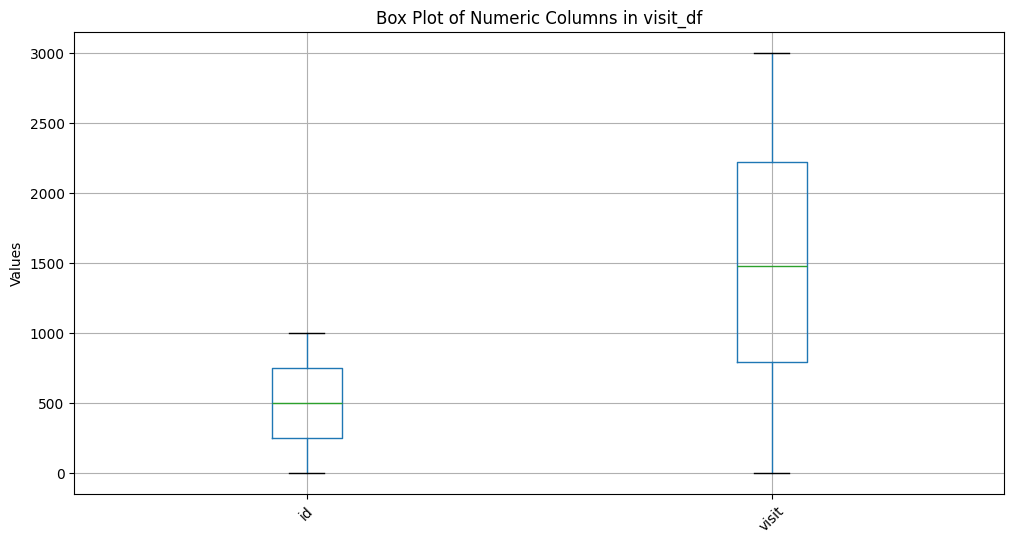

In [40]:
# Create box plots for all numeric columns in visit_df to visually check for outliers
plt.figure(figsize=(12, 6))
visit_df.select_dtypes(include='number').boxplot()
plt.title('Box Plot of Numeric Columns in visit_df')
plt.ylabel('Values')
plt.xticks(rotation=45)
plt.show()

### 7. Get rid of any outliers.

In [41]:
# Remove outliers from visit_df again using the IQR method for all numeric columns
cleaned_df = visit_df.copy()
for col in cleaned_df.select_dtypes(include='number').columns:
    Q1 = cleaned_df[col].quantile(0.25)
    Q3 = cleaned_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    cleaned_df = cleaned_df[(cleaned_df[col] >= lower_bound) & (cleaned_df[col] <= upper_bound)]

print(f"Number of records after removing outliers: {len(cleaned_df)}")

Number of records after removing outliers: 974


## Activity 5

### Create a series and practice basic arithmetic steps

In [42]:
# Create Series 1
s1 = pd.Series([7.3, -2.5, 3.4, 1.5], index=['a', 'c', 'd', 'e'])

# Create Series 2
s2 = pd.Series([-2.1, 3.6, -1.5, 4, 3.1], index=['a', 'c', 'e', 'f', 'g'])

# Add Series 1 and Series 2
addition_result = s1 + s2
print("Addition (s1 + s2):")
print(addition_result)

# Subtract Series 1 from Series 2
subtraction_result = s2 - s1
print("\nSubtraction (s2 - s1):")
print(subtraction_result)


Addition (s1 + s2):
a    5.2
c    1.1
d    NaN
e    0.0
f    NaN
g    NaN
dtype: float64

Subtraction (s2 - s1):
a   -9.4
c    6.1
d    NaN
e   -3.0
f    NaN
g    NaN
dtype: float64


Insert data into a SQL Lite database – create a table with the following data below that you will create yourself (Hint on how to create the SQL: Python for Data Analysis 2nd edition page 191, Python for Data Analysis 3rd Edition: Page 199):
a. Name, Address, City, State, Zip, Phone Number
b. Add at least 10 rows of data and submit your code with a query generating your results.

In [43]:


# Create a connection to a new SQLite database in memory (or use a file: 'contacts.db')
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

# Create the table
cursor.execute('''
    CREATE TABLE contacts (
        Name TEXT,
        Address TEXT,
        City TEXT,
        State TEXT,
        Zip TEXT,
        PhoneNumber TEXT
    )
''')

# Sample data (at least 10 rows)
data = [
    ('Alice Smith', '123 Maple St', 'Springfield', 'IL', '62704', '217-555-1234'),
    ('Bob Johnson', '456 Oak Ave', 'Chicago', 'IL', '60616', '312-555-5678'),
    ('Carol Lee', '789 Pine Rd', 'Peoria', 'IL', '61602', '309-555-8765'),
    ('David Kim', '321 Birch Ln', 'Naperville', 'IL', '60540', '630-555-4321'),
    ('Eva Brown', '654 Cedar Dr', 'Evanston', 'IL', '60201', '847-555-2468'),
    ('Frank White', '987 Elm St', 'Rockford', 'IL', '61101', '815-555-1357'),
    ('Grace Green', '159 Spruce Ct', 'Aurora', 'IL', '60505', '630-555-9753'),
    ('Henry Black', '753 Willow Way', 'Joliet', 'IL', '60431', '815-555-8642'),
    ('Ivy Blue', '852 Aspen Pl', 'Elgin', 'IL', '60120', '847-555-3579'),
    ('Jack Gray', '951 Poplar Blvd', 'Waukegan', 'IL', '60085', '224-555-4682')
]

# Insert data into the table
cursor.executemany('INSERT INTO contacts VALUES (?, ?, ?, ?, ?, ?)', data)
conn.commit()

# Query and display the results
df_contacts = pd.read_sql_query('SELECT * FROM contacts', conn)
print(df_contacts)

# Close the connection
conn.close()

          Name          Address         City State    Zip   PhoneNumber
0  Alice Smith     123 Maple St  Springfield    IL  62704  217-555-1234
1  Bob Johnson      456 Oak Ave      Chicago    IL  60616  312-555-5678
2    Carol Lee      789 Pine Rd       Peoria    IL  61602  309-555-8765
3    David Kim     321 Birch Ln   Naperville    IL  60540  630-555-4321
4    Eva Brown     654 Cedar Dr     Evanston    IL  60201  847-555-2468
5  Frank White       987 Elm St     Rockford    IL  61101  815-555-1357
6  Grace Green    159 Spruce Ct       Aurora    IL  60505  630-555-9753
7  Henry Black   753 Willow Way       Joliet    IL  60431  815-555-8642
8     Ivy Blue     852 Aspen Pl        Elgin    IL  60120  847-555-3579
9    Jack Gray  951 Poplar Blvd     Waukegan    IL  60085  224-555-4682
